# Sobol SA on T1 Mortality — All 4 Policies (Degraded Distances)

Extended distance ranges: same_bn 10-40, inter_bn 15-70.
One Sobol decomposition per policy, side by side.

In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from SALib.analyze import sobol as sobol_analyze

RESULTS_PATH = _root / "data_cluster" / "loose_ranges" / "results.csv"
df = pd.read_csv(RESULTS_PATH)
print(f"Loaded {len(df)} runs")

UNCERTAINTIES = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]
BOUNDS_MAP = dict(zip(UNCERTAINTIES, [[10, 40], [15, 70], [0.01, 0.07], [1, 6], [1, 60]]))
UNCERTAINTIES_SORTED = sorted(UNCERTAINTIES)
BOUNDS_SORTED = [BOUNDS_MAP[u] for u in UNCERTAINTIES_SORTED]

problem = {
    "num_vars": len(UNCERTAINTIES),
    "names": UNCERTAINTIES_SORTED,
    "bounds": BOUNDS_SORTED,
}

OUTCOME = "death_rate_T1_BCAS"

policies = [
    ("Stovepipe",  0, 0),
    ("Amb only",   0, 1),
    ("Fac only",   1, 0),
    ("Both",       1, 1),
]

results = {}
for label, fac, amb in policies:
    sub = df[(df["facility_eligibility"] == fac) & (df["ambulance_eligibility"] == amb)].sort_values("scenario").reset_index(drop=True)
    N = len(sub) // (2 * problem["num_vars"] + 2)
    print(f"{label}: {len(sub)} runs, N={N}")
    Si = sobol_analyze.analyze(problem, sub[OUTCOME].values, calc_second_order=True)
    results[label] = Si

Loaded 98304 runs
Stovepipe: 24576 runs, N=2048


Amb only: 24576 runs, N=2048


Fac only: 24576 runs, N=2048


Both: 24576 runs, N=2048


## S1 and ST — All 4 Policies

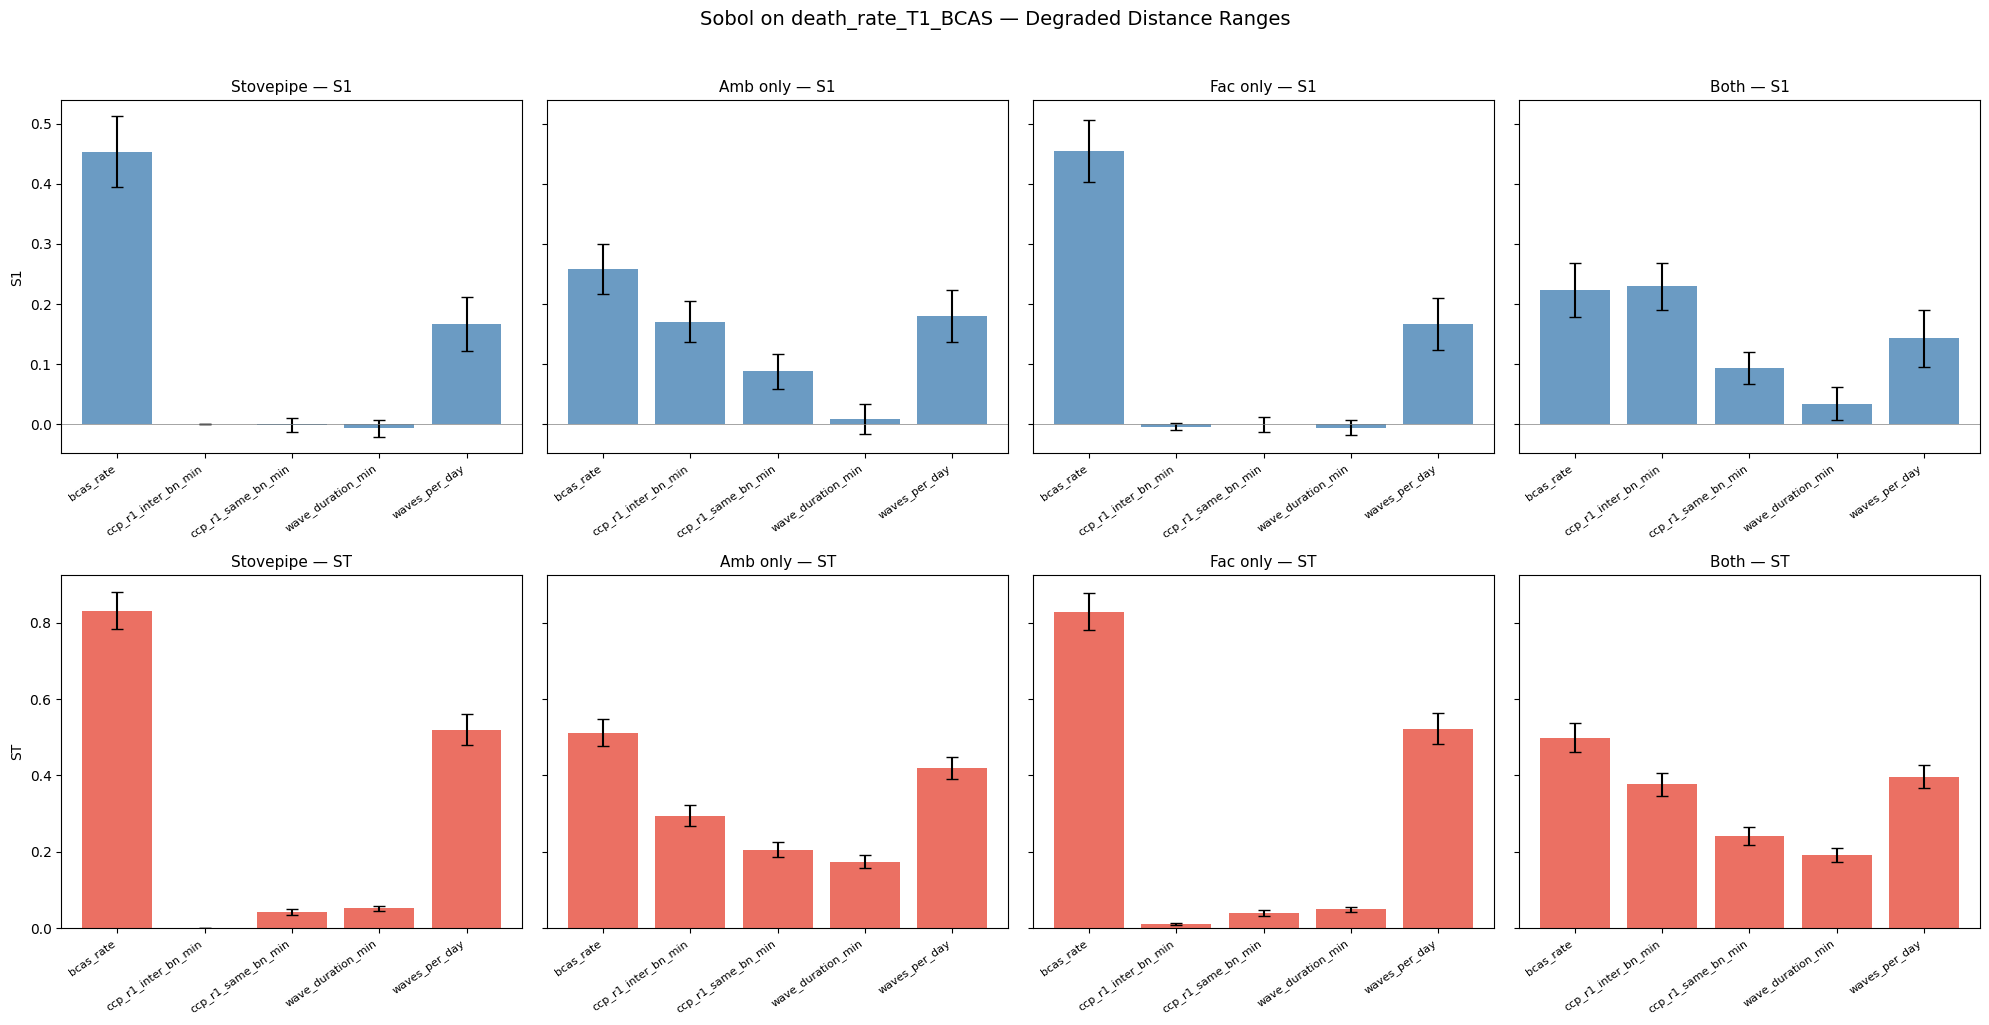

In [2]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10), sharey="row")
x_pos = np.arange(len(UNCERTAINTIES_SORTED))
colors_s1 = "steelblue"
colors_st = "#e74c3c"

for j, (label, _, _) in enumerate(policies):
    Si = results[label]
    axes[0, j].bar(x_pos, Si["S1"], yerr=Si["S1_conf"], capsize=4, color=colors_s1, alpha=0.8)
    axes[0, j].set_xticks(x_pos)
    axes[0, j].set_xticklabels(UNCERTAINTIES_SORTED, rotation=35, ha="right", fontsize=8)
    axes[0, j].set_title(f"{label} — S1", fontsize=11)
    axes[0, j].axhline(0, color="grey", linewidth=0.5)
    if j == 0:
        axes[0, j].set_ylabel("S1")

    axes[1, j].bar(x_pos, Si["ST"], yerr=Si["ST_conf"], capsize=4, color=colors_st, alpha=0.8)
    axes[1, j].set_xticks(x_pos)
    axes[1, j].set_xticklabels(UNCERTAINTIES_SORTED, rotation=35, ha="right", fontsize=8)
    axes[1, j].set_title(f"{label} — ST", fontsize=11)
    axes[1, j].axhline(0, color="grey", linewidth=0.5)
    if j == 0:
        axes[1, j].set_ylabel("ST")

fig.suptitle(f"Sobol on {OUTCOME} — Degraded Distance Ranges", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## Summary Table

In [3]:
for label, _, _ in policies:
    Si = results[label]
    print(f"\n=== {label} ===")
    print(pd.DataFrame({"S1": Si["S1"], "S1_conf": Si["S1_conf"], "ST": Si["ST"], "ST_conf": Si["ST_conf"]}, index=UNCERTAINTIES_SORTED).to_string(float_format="%.4f"))


=== Stovepipe ===
                         S1  S1_conf     ST  ST_conf
bcas_rate            0.4532   0.0591 0.8320   0.0486
ccp_r1_inter_bn_min  0.0000   0.0000 0.0000   0.0000
ccp_r1_same_bn_min  -0.0018   0.0119 0.0416   0.0081
wave_duration_min   -0.0069   0.0143 0.0517   0.0073
waves_per_day        0.1673   0.0449 0.5205   0.0403

=== Amb only ===
                        S1  S1_conf     ST  ST_conf
bcas_rate           0.2590   0.0418 0.5119   0.0353
ccp_r1_inter_bn_min 0.1708   0.0345 0.2945   0.0270
ccp_r1_same_bn_min  0.0880   0.0292 0.2060   0.0208
wave_duration_min   0.0088   0.0258 0.1737   0.0168
waves_per_day       0.1806   0.0432 0.4198   0.0294

=== Fac only ===
                         S1  S1_conf     ST  ST_conf
bcas_rate            0.4545   0.0520 0.8294   0.0492
ccp_r1_inter_bn_min -0.0037   0.0052 0.0111   0.0028
ccp_r1_same_bn_min  -0.0001   0.0120 0.0390   0.0082
wave_duration_min   -0.0055   0.0127 0.0490   0.0066
waves_per_day        0.1667   0.0438 0.5227   0.04

## S2 — Pairwise Interactions

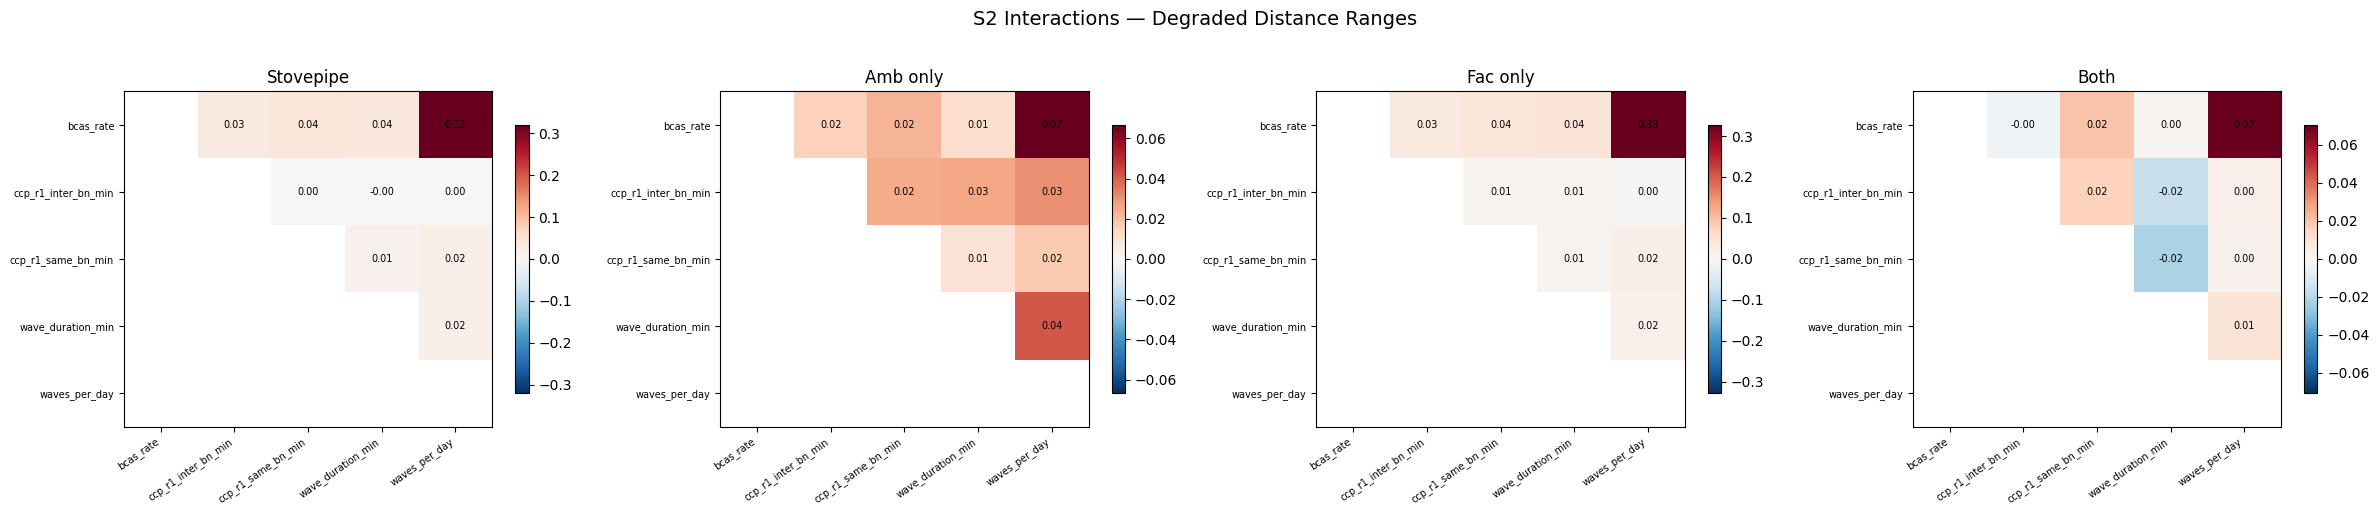

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(24, 5))

for j, (label, _, _) in enumerate(policies):
    Si = results[label]
    S2 = pd.DataFrame(Si["S2"], index=UNCERTAINTIES_SORTED, columns=UNCERTAINTIES_SORTED)
    S2_conf = pd.DataFrame(Si["S2_conf"], index=UNCERTAINTIES_SORTED, columns=UNCERTAINTIES_SORTED)
    mask = np.tril(np.ones_like(S2, dtype=bool), k=0)
    s2_masked = S2.where(~mask)
    vabs = max(0.01, np.nanmax(np.abs(s2_masked.values.astype(float))))
    im = axes[j].imshow(s2_masked.values.astype(float), cmap="RdBu_r", vmin=-vabs, vmax=vabs, aspect="auto")
    axes[j].set_xticks(range(len(UNCERTAINTIES_SORTED)))
    axes[j].set_xticklabels(UNCERTAINTIES_SORTED, rotation=35, ha="right", fontsize=7)
    axes[j].set_yticks(range(len(UNCERTAINTIES_SORTED)))
    axes[j].set_yticklabels(UNCERTAINTIES_SORTED, fontsize=7)
    axes[j].set_title(f"{label}")
    for i in range(len(UNCERTAINTIES_SORTED)):
        for k in range(len(UNCERTAINTIES_SORTED)):
            if not mask[i, k]:
                v = S2.iloc[i, k]
                if not np.isnan(v):
                    axes[j].text(k, i, f"{v:.2f}", ha="center", va="center", fontsize=7)
    plt.colorbar(im, ax=axes[j], shrink=0.8)

fig.suptitle("S2 Interactions — Degraded Distance Ranges", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()